# DFT & Solvation New Variables (`DFT_new_variables`)

|                     |     |
| ------------------- | --- |
| **Status**          | Active analysis, 2026-11-10 |
| **Source**          | `data/tank/tms_v1/molecules.jsonl`, `data/tank/tms_v1/solvation_cosmors.jsonl`, `data/solvation_energies.json`, `notebooks/results/thermo3_2pct_0p5pct/` |
| **Scope**           | Calculate, tabulate, and plot the **three simple physical variables** already stored in the DFT/solvation database that are not yet used by the baseline model |
| **Related docs**    | `docs/private/theory-scientific_concerns_and_scalability.md` |

---

### Why These Three Variables?

The current thermodynamic and microkinetic pipeline (`kinetics/thermo/equilibrium.py` and `kinetics/microkinetics/rates.py`) uses only **one scalar per species from DFT** ($G_{\text{gas}, i}^\circ(298.15\text{ K})$) and **one scalar per species from MD** ($\Delta E_{\text{solv}, i}$ in `1:1 EC/DEC`).

Without adding new unknown fitting parameters or unverified reaction pathways, the `tms_v1` DFT & COSMO-RS snapshot already contains **three simple, physically transparent variables** that explain key experimental and modeling questions:

1. **Variable 1 — Hydrogen-Bond Donor & Acceptor Strength (`sigma_hb_don`, `sigma_hb_acc`) & Dipole (`dipole_debye`)**
   - Every hydrolysis step (`TMSPA` $\to$ `BMSPA` $\to$ `MMSPA` $\to$ `H3PO4`) replaces a hydrophobic $-\text{Si(CH}_3)_3$ group with a polar, hydrogen-bond-donating $-\text{OH}$ group.
   - `sigma_hb_don` increases almost linearly with the number of $-\text{OH}$ groups ($0.00 \to 6.52 \to 14.28 \to 23.52$), physically explaining why polar `EC` stabilizes hydrolysed phosphates and `H2O` much more strongly than apolar `DEC`, and why the empirical thermodynamic fit shifts $\delta E_{\text{solv}, i}$ move systematically along the hydrolysis ladder.

2. **Variable 2 — Gas-Phase Entropy ($T_0 S_{\text{gas}}^\circ = H_{\text{gas}}^\circ - G_{\text{gas}}^\circ$) & Temperature-Dependent $\Delta G_{\text{rxn}}(T)$ ($20\text{--}80\,^\circ\text{C}$)**
   - Currently, $G_{\text{gas}, i}$ is evaluated at $T_{\text{DFT}} = 298.15\text{ K}$ ($25\,^\circ\text{C}$) and held constant even when an NMR tube is heated to $50\,^\circ\text{C}$ or $80\,^\circ\text{C}$.
   - Because both `enthalpy_eh` ($H_{\text{gas}}^\circ$) and `gibbs_eh` ($G_{\text{gas}}^\circ$) are stored in `molecules.jsonl`, we can directly extract $S_{\text{gas}, i}^\circ = (H_{\text{gas}, i}^\circ - G_{\text{gas}, i}^\circ) / T_0$ and compute exact temperature-dependent reaction free energies:
     $$\Delta G_{\text{rxn}, j}(T) = \Delta H_{\text{gas}, j}^\circ - T\,\Delta S_{\text{gas}, j}^\circ + \Delta\Delta E_{\text{solv}, j}$$

3. **Variable 3 — COSMO-RS Miscibility (`lle`: `"miscible"` vs. `"split"`), Activity Coefficient ($\ln \gamma^\infty$), & Solvation Across Solvents (`EC` vs. `DEC` and 7 Solvents)**
   - In `solvation_cosmors`, openCOSMO-RS provides $\Delta G_{\text{solv}}$, the infinite-dilution activity coefficient $\ln \gamma^\infty$, and the liquid-liquid equilibrium phase-split flag `lle` (`"miscible"` vs. `"split"`) across 7 solvents (`EC`, `DEC`, `DMC`, `PC`, `DME`, `DMSO`, `H2O`).
   - Crucially, **neither pure `EC` nor pure `DEC` is miscible with the entire reaction network**: in **pure `DEC`**, polar `H2O` ($\ln \gamma^\infty = +3.36$) and `H3PO4` ($\ln \gamma^\infty = +4.88$) are flagged as **`"lle": "split"` (phase-separating)** while silylated species (`TMSPA`, `HMDSO`, `TMSOH`) are `"miscible"`. Conversely, in **neat `EC`**, `H2O` and `H3PO4` are `"miscible"`, while apolar silylated species (`TMSPA`, `BMSPA`, `MMSPA`, `HMDSO`, `TMSOH`) are flagged as `"split"`.


In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "kinetics").is_dir() else Path.cwd().parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from demo.style import INK, INK_MUTED as MUTED, SERIES, apply_style
from kinetics.constants import EV_TO_J, EV_TO_KJ_MOL, HARTREE_TO_EV, KB_SI, KCAL_EV, KJ_MOL_TO_EV, T_STD_K
from kinetics.data import (
    DEFAULT_MEDIUM, NETWORK, NETWORK_SPECIES,
    build_stoichiometric_matrix, format_equation, get_active_medium, get_solvent, load_snapshot,
)
from kinetics.data.species import resolve_species_database
from kinetics.fitting.config import apply_fit_config

KB_EV_PER_K = KB_SI / EV_TO_J
T_DFT_REF_K = T_STD_K

def show_table(df):
    display(df)

apply_style()


In [2]:
# 1. Activate the 2026-10-08 snapshot & 1:1 EC/DEC medium used by the fits, then load DFT, MD, and COSMO-RS records
apply_fit_config(REPO / "notebooks" / "results" / "thermo3_2pct_0p5pct")
medium = get_active_medium()
snap = load_snapshot(medium.path)
db = resolve_species_database()

mol_by_id = {rec["pipeline_id"]: rec for rec in snap["datasets"]}

cosmo_by_id = {}
for row in snap["cosmors"]["rows"]:
    cosmo_by_id.setdefault(row["solute_pipeline_id"], {})[row["solvent_pipeline_id"]] = row

md_by_solvent = {"EC": {}, "DEC": {}}
for rec in snap["solvation"]:
    sp_name = rec["raw_metadata"]["name"]
    sv = get_solvent(rec)
    if sv in md_by_solvent:
        md_by_solvent[sv][sp_name] = rec

# 2. Load the 11-species, 9-reaction kinetic/thermodynamic network and 1:1 EC/DEC medium
MODEL_SPECIES = list(NETWORK_SPECIES)
RXN_LIST = [{"id": k, **v} for k, v in NETWORK.items()]
S_mat = build_stoichiometric_matrix(NETWORK, MODEL_SPECIES)  # shape: (11 species, 9 reactions)
ALL_SPECIES = sorted(mol_by_id.keys(), key=lambda s: (0 if s in MODEL_SPECIES else 1, MODEL_SPECIES.index(s) if s in MODEL_SPECIES else 99, s))

# 3. Load fitted thermodynamic solvation shifts (δE_solv,i in eV) from thermo3_2pct_0p5pct and thermo2_2pctH2O (Step 3, ξ=1)
def load_thermo_shifts(run_name: str, xi: int = 1) -> dict[str, float]:
    steps_dir = REPO / "notebooks" / "results" / run_name / "steps"
    if not steps_dir.exists():
        return {}
    matches = sorted(steps_dir.glob(f"thermo__*_xi{xi}.json"))
    if not matches:
        return {}
    fit = json.loads(matches[-1].read_text())
    return fit.get("species_shifts_eV") or {}

shifts_thermo3 = load_thermo_shifts("thermo3_2pct_0p5pct", xi=1)
shifts_thermo2 = load_thermo_shifts("thermo2_2pctH2O", xi=1)
mf = medium.mole_fractions()

print(f"Loaded {len(mol_by_id)} DFT molecules ({len(MODEL_SPECIES)} in active model: {', '.join(MODEL_SPECIES)})")
print(f"Loaded COSMO-RS records for {len(cosmo_by_id)} molecules across 7 solvents: {list(next(iter(cosmo_by_id.values())).keys())}")
print(f"Mixture mole fractions ({medium.label}): x_EC = {mf['EC']:.3f}, x_DEC = {mf['DEC']:.3f}")


Loaded 27 DFT molecules (11 in active model: TMSPA, BMSPA, MMSPA, H3PO4, H2O, TMSOH, HMDSO, EC, TMSOEG, TMSOdiEG, CO2)
Loaded COSMO-RS records for 24 molecules across 7 solvents: ['EC', 'DEC', 'DMC', 'DME', 'DMSO', 'propylene_carbonate', 'H2O']
Mixture mole fractions (<bound method SolvationMedium.label of SolvationMedium(snapshot='tank_api_snapshot_2026-10-08.json', volume_fractions=(('EC', 0.5), ('DEC', 0.5)), rule='linear')>): x_EC = 0.645, x_DEC = 0.355


---
## 1. Variable 1 — Hydrogen-Bonding (`sigma_hb_don`, `sigma_hb_acc`) & Dipole (`dipole_debye`)

### Physical Meaning
In the COSMO-RS $\sigma$-profile framework, the surface screening charge density $\sigma$ of each molecule's DFT cavity is integrated over strongly positive and strongly negative polar regions to give two descriptors:
- **`sigma_hb_don` (H-bond donor moment):** Measures how strongly acidic hydrogens (such as $-\text{POH}$, $-\text{SiOH}$, and $\text{H}_2\text{O}$) can donate hydrogen bonds to a solvent acceptor.
- **`sigma_hb_acc` (H-bond acceptor moment):** Measures how strongly lone-pair oxygens ($\text{P}=\text{O}$, $\text{C}=\text{O}$, $\text{Si}-\text{O}-\text{Si}$, $\text{H}_2\text{O}$) can accept hydrogen bonds.
- **`dipole_debye` ($\mu$, in Debye):** Measures the overall permanent electric dipole of the gas-phase DFT geometry.

Let us build the complete species table for the 11 active model species (and compare with the remaining 16 database molecules) alongside their `EC` vs. `DEC` solvation energies and fitted thermodynamic shifts $\delta E_{\text{solv}, i}$.


In [3]:
OH_COUNT = {
    "TMSPA": 0, "BMSPA": 1, "MMSPA": 2, "H3PO4": 3,
    "HMDSO": 0, "TMSOH": 1, "H2O": 2,
    "EC": 0, "TMSOEG": 0, "TMSOdiEG": 0, "CO2": 0,
}

FAMILY_GROUP = {
    "TMSPA": "Phosphate ladder", "BMSPA": "Phosphate ladder", "MMSPA": "Phosphate ladder", "H3PO4": "Phosphate ladder",
    "HMDSO": "Silyl / Water", "TMSOH": "Silyl / Water", "H2O": "Silyl / Water",
    "EC": "Carbonate / Glycol", "TMSOEG": "Carbonate / Glycol", "TMSOdiEG": "Carbonate / Glycol", "CO2": "Carbonate / Glycol",
}

KJ_TO_EV = 1.0 / EV_TO_KJ_MOL
KCAL_TO_EV = 4.184 / EV_TO_KJ_MOL

rows_v1 = []
for sp in ALL_SPECIES:
    m = mol_by_id[sp]
    md_ec = md_by_solvent["EC"].get(sp, {}).get("delta_e_solv_kjmol")
    md_dec = md_by_solvent["DEC"].get(sp, {}).get("delta_e_solv_kjmol")
    md_ec_ev = md_ec * KJ_TO_EV if md_ec is not None else np.nan
    md_dec_ev = md_dec * KJ_TO_EV if md_dec is not None else np.nan
    md_mix_ev = (
        mf["EC"] * md_ec_ev + mf["DEC"] * md_dec_ev
        if (np.isfinite(md_ec_ev) and np.isfinite(md_dec_ev)) else np.nan
    )
    cos_ec = cosmo_by_id.get(sp, {}).get("EC", {}).get("dg_solv_kcal_mol")
    cos_dec = cosmo_by_id.get(sp, {}).get("DEC", {}).get("dg_solv_kcal_mol")
    cos_ec_ev = cos_ec * KCAL_TO_EV if cos_ec is not None else np.nan
    cos_dec_ev = cos_dec * KCAL_TO_EV if cos_dec is not None else np.nan

    rows_v1.append({
        "Species": sp,
        "In model": "Yes" if sp in MODEL_SPECIES else "No",
        "Group": FAMILY_GROUP.get(sp, "Other DFT"),
        "-OH count": OH_COUNT.get(sp, np.nan),
        "sigma_hb_don": m.get("sigma_hb_don", np.nan),
        "sigma_hb_acc": m.get("sigma_hb_acc", np.nan),
        "Dipole (D)": m.get("dipole_debye", np.nan),
        "Polarizability (Å³)": m.get("polarizability_iso_ang3", np.nan),
        "MD EC (eV)": md_ec_ev,
        "MD DEC (eV)": md_dec_ev,
        "MD Δ(EC−DEC) (eV)": md_ec_ev - md_dec_ev,
        "COSMO EC (eV)": cos_ec_ev,
        "COSMO DEC (eV)": cos_dec_ev,
        "COSMO Δ(EC−DEC) (eV)": cos_ec_ev - cos_dec_ev,
        "MD mix − COSMO EC (eV)": md_mix_ev - cos_ec_ev,
        "Thermo3 shift δE_solv (eV)": shifts_thermo3.get(sp, 0.0 if sp in ("H2O", "EC") else np.nan),
        "Thermo2 shift δE_solv (eV)": shifts_thermo2.get(sp, 0.0 if sp in ("H2O", "EC") else np.nan),
    })

df_v1 = pd.DataFrame(rows_v1)
df_v1_model = df_v1[df_v1["In model"] == "Yes"].reset_index(drop=True)

display(Markdown("#### Table 1A — H-Bond Donor/Acceptor, Dipole & Solvation Preferences for the 11 Active Model Species"))
show_table(
    df_v1_model[[
        "Species", "Group", "-OH count", "sigma_hb_don", "sigma_hb_acc", "Dipole (D)",
        "MD EC (eV)", "MD DEC (eV)", "MD Δ(EC−DEC) (eV)",
        "COSMO Δ(EC−DEC) (eV)", "Thermo3 shift δE_solv (eV)"
    ]].round(3)
)


#### Table 1A — H-Bond Donor/Acceptor, Dipole & Solvation Preferences for the 11 Active Model Species

,Species,Group,-OH count,sigma_hb_don,sigma_hb_acc,Dipole (D),MD EC (eV),MD DEC (eV),MD Δ(EC−DEC) (eV),COSMO Δ(EC−DEC) (eV),Thermo3 shift δE_solv (eV)
0,TMSPA,Phosphate ladder,0.0,0.000,9.816,0.699,-0.743,-1.251,0.508,0.135,-0.085
1,BMSPA,Phosphate ladder,1.0,6.522,11.324,1.041,-1.413,-1.100,-0.313,0.059,0.040
2,MMSPA,Phosphate ladder,2.0,14.283,12.619,0.839,-1.719,-1.437,-0.281,-0.018,0.073
3,H3PO4,Phosphate ladder,3.0,23.521,12.887,0.461,-2.076,-1.461,-0.615,-0.098,0.014
4,H2O,Silyl / Water,2.0,7.514,8.062,1.865,-0.861,-0.868,0.007,-0.047,-0.070
5,TMSOH,Silyl / Water,1.0,3.634,6.002,1.307,-0.907,-0.823,-0.084,0.024,0.080
6,HMDSO,Silyl / Water,0.0,0.000,1.449,0.507,-0.594,-0.785,0.191,0.103,0.080
7,EC,Carbonate / Glycol,0.0,0.615,7.282,5.445,-0.666,-0.854,0.188,-0.042,-0.079
8,TMSOEG,Carbonate / Glycol,0.0,1.548,7.997,2.456,-0.932,-0.749,-0.184,0.047,0.073
9,TMSOdiEG,Carbonate / Glycol,0.0,1.932,10.897,2.069,-0.931,-1.060,0.129,0.056,-0.084


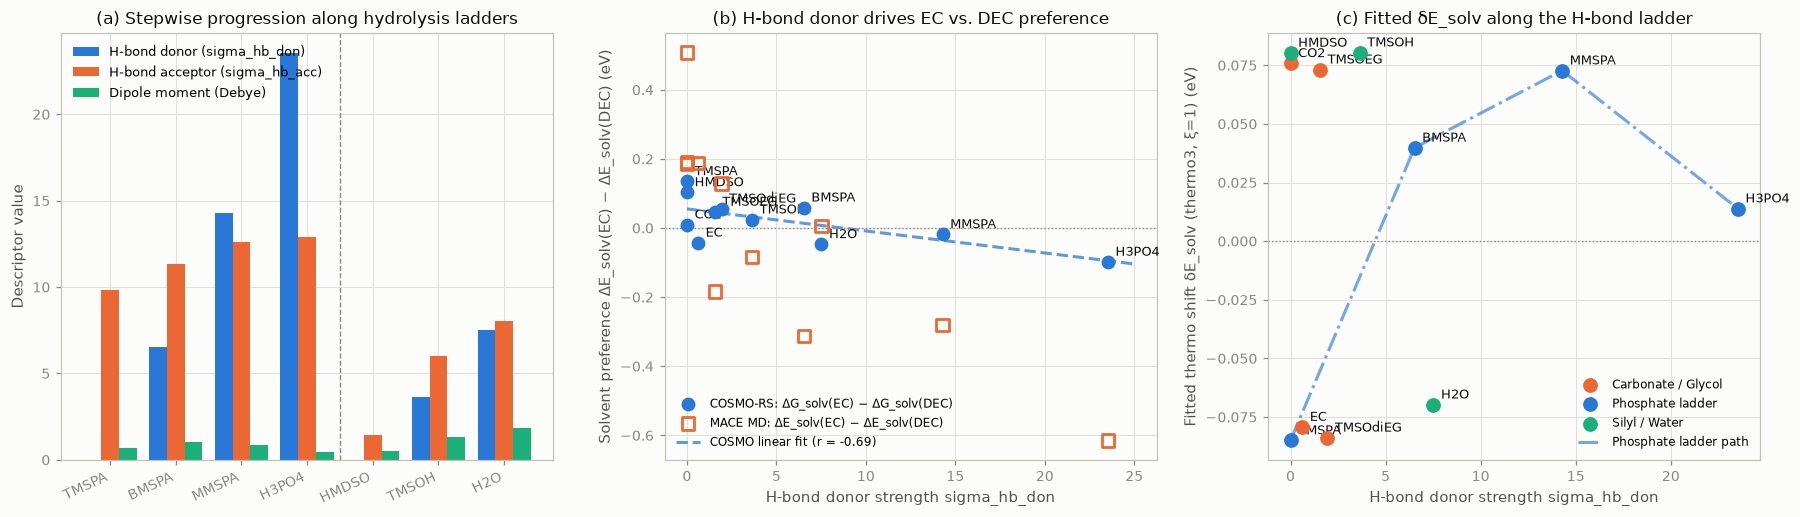

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel (a): Stepwise progression along the phosphate hydrolysis ladder & silyl pair
ax = axes[0]
ladder = ["TMSPA", "BMSPA", "MMSPA", "H3PO4", "HMDSO", "TMSOH", "H2O"]
sub_lad = df_v1_model.set_index("Species").loc[ladder]
x = np.arange(len(ladder))
w = 0.27
ax.bar(x - w, sub_lad["sigma_hb_don"], width=w, color=SERIES[0], label="H-bond donor (sigma_hb_don)")
ax.bar(x, sub_lad["sigma_hb_acc"], width=w, color=SERIES[1], label="H-bond acceptor (sigma_hb_acc)")
ax.bar(x + w, sub_lad["Dipole (D)"], width=w, color=SERIES[2], label="Dipole moment (Debye)")
ax.axvline(3.5, color=MUTED, linestyle="--", linewidth=0.9)
ax.set_xticks(x)
ax.set_xticklabels(ladder, rotation=25, ha="right")
ax.set_ylabel("Descriptor value")
ax.set_title("(a) Stepwise progression along hydrolysis ladders")
ax.legend(loc="upper left", fontsize=8.5)

# Panel (b): sigma_hb_don vs Solvent Preference Δ(EC - DEC) in COSMO-RS & MD
ax = axes[1]
valid_b = df_v1_model.dropna(subset=["sigma_hb_don", "COSMO Δ(EC−DEC) (eV)"])
ax.scatter(
    valid_b["sigma_hb_don"], valid_b["COSMO Δ(EC−DEC) (eV)"],
    s=65, color=SERIES[0], label="COSMO-RS: ΔG_solv(EC) − ΔG_solv(DEC)", zorder=4
)
ax.scatter(
    valid_b["sigma_hb_don"], valid_b["MD Δ(EC−DEC) (eV)"],
    s=65, marker="s", facecolors="none", edgecolors=SERIES[1], linewidths=1.8,
    label="MACE MD: ΔE_solv(EC) − ΔE_solv(DEC)", zorder=4
)
# Linear trend on COSMO-RS Δ(EC - DEC) vs sigma_hb_don
m_slope, b_int = np.polyfit(valid_b["sigma_hb_don"], valid_b["COSMO Δ(EC−DEC) (eV)"], 1)
xx = np.linspace(0, 25, 100)
r_corr = np.corrcoef(valid_b["sigma_hb_don"], valid_b["COSMO Δ(EC−DEC) (eV)"])[0, 1]
ax.plot(xx, m_slope * xx + b_int, "--", color=SERIES[0], alpha=0.75, label=f"COSMO linear fit (r = {r_corr:.2f})")
for _, r in valid_b.iterrows():
    ax.annotate(
        r["Species"], (r["sigma_hb_don"], r["COSMO Δ(EC−DEC) (eV)"]),
        xytext=(5, 4), textcoords="offset points", fontsize=8.5, color=INK
    )
ax.axhline(0, color=MUTED, linestyle=":", linewidth=0.9)
ax.set_xlabel("H-bond donor strength sigma_hb_don")
ax.set_ylabel("Solvent preference ΔE_solv(EC) − ΔE_solv(DEC) (eV)")
ax.set_title("(b) H-bond donor drives EC vs. DEC preference")
ax.legend(loc="lower left", fontsize=8)

# Panel (c): Fitted thermodynamic solvation shift δE_solv vs sigma_hb_don (colored by group)
ax = axes[2]
valid_c = df_v1_model.dropna(subset=["Thermo3 shift δE_solv (eV)"]).copy()
group_colors = {"Phosphate ladder": SERIES[0], "Silyl / Water": SERIES[2], "Carbonate / Glycol": SERIES[1]}
for grp, grp_df in valid_c.groupby("Group"):
    ax.scatter(
        grp_df["sigma_hb_don"], grp_df["Thermo3 shift δE_solv (eV)"],
        s=75, color=group_colors.get(grp, SERIES[3]), label=grp, zorder=4
    )
# Connect the phosphate ladder in order TMSPA -> BMSPA -> MMSPA -> H3PO4
phos_c = valid_c.set_index("Species").loc[["TMSPA", "BMSPA", "MMSPA", "H3PO4"]]
ax.plot(phos_c["sigma_hb_don"], phos_c["Thermo3 shift δE_solv (eV)"], "-.", color=SERIES[0], alpha=0.65, label="Phosphate ladder path")
for _, r in valid_c.iterrows():
    ax.annotate(
        r["Species"], (r["sigma_hb_don"], r["Thermo3 shift δE_solv (eV)"]),
        xytext=(5, 4), textcoords="offset points", fontsize=8.5, color=INK
    )
ax.axhline(0, color=MUTED, linestyle=":", linewidth=0.9)
ax.set_xlabel("H-bond donor strength sigma_hb_don")
ax.set_ylabel("Fitted thermo shift δE_solv (thermo3, ξ=1) (eV)")
ax.set_title("(c) Fitted δE_solv along the H-bond ladder")
ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()


#### Table 1B — Reaction-Level H-Bond & Dipole Changes ($\Delta = \sum_i s_{i,j} X_i$) Across `R1`–`R9`

,Reaction,Family,Equation,Δsigma_hb_don,Δsigma_hb_acc,ΔDipole (D),ΔΔE_solv MD (EC−DEC) (eV),ΔΔG_solv COSMO (EC−DEC) (eV),Δ(δE_solv) Thermo3 (eV)
0,R1,hydrolysis,TMSPA + H2O ⇌ BMSPA + TMSOH,2.642,-0.552,-0.216,-0.912,-0.005,0.275
1,R2,hydrolysis,BMSPA + H2O ⇌ MMSPA + TMSOH,3.881,-0.766,-0.759,-0.059,-0.006,0.183
2,R3,hydrolysis,MMSPA + H2O ⇌ H3PO4 + TMSOH,5.358,-1.792,-0.936,-0.424,-0.008,0.091
3,R4,condensation,2 TMSOH ⇌ HMDSO + H2O,0.246,-2.492,-0.243,0.366,0.008,-0.150
4,R5,transfer,TMSPA + TMSOH ⇌ BMSPA + HMDSO,2.887,-3.044,-0.459,-0.546,0.003,0.125
5,R6,transfer,BMSPA + TMSOH ⇌ MMSPA + HMDSO,4.127,-3.258,-1.002,0.307,0.001,0.033
6,R7,transfer,MMSPA + TMSOH ⇌ H3PO4 + HMDSO,5.604,-4.284,-1.178,-0.058,-0.001,-0.059
7,R8,solvent_attack,EC + TMSOH ⇌ TMSOEG + CO2,-2.701,-5.287,-4.295,-0.103,0.075,0.148
8,R9,solvent_attack,EC + TMSOEG ⇌ TMSOdiEG + CO2,-0.231,-4.383,-5.832,0.309,0.062,-0.002


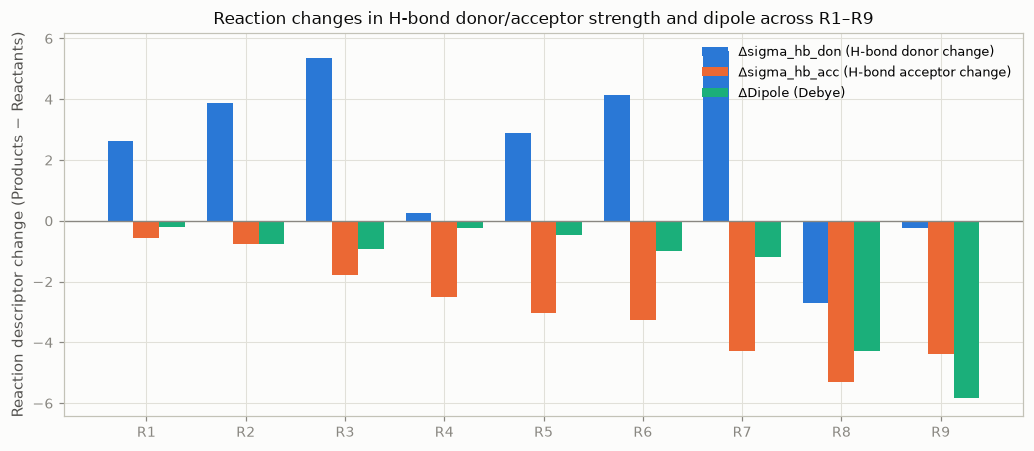

In [5]:
# Compute reaction-level Δsigma_hb_don, Δsigma_hb_acc, ΔDipole, and ΔΔE_solv across R1-R9
sp_idx = {sp: i for i, sp in enumerate(MODEL_SPECIES)}
v1_indexed = df_v1_model.set_index("Species")

rxn_v1_rows = []
for j, rxn in enumerate(RXN_LIST):
    nu = S_mat[:, j]
    d_hb_don = float(sum(nu[i] * v1_indexed.loc[sp, "sigma_hb_don"] for i, sp in enumerate(MODEL_SPECIES)))
    d_hb_acc = float(sum(nu[i] * v1_indexed.loc[sp, "sigma_hb_acc"] for i, sp in enumerate(MODEL_SPECIES)))
    d_dipole = float(sum(nu[i] * v1_indexed.loc[sp, "Dipole (D)"] for i, sp in enumerate(MODEL_SPECIES)))
    ddE_md_ec = float(sum(nu[i] * v1_indexed.loc[sp, "MD EC (eV)"] for i, sp in enumerate(MODEL_SPECIES)))
    ddE_md_dec = float(sum(nu[i] * v1_indexed.loc[sp, "MD DEC (eV)"] for i, sp in enumerate(MODEL_SPECIES)))
    ddG_cos_ec = float(sum(nu[i] * v1_indexed.loc[sp, "COSMO EC (eV)"] for i, sp in enumerate(MODEL_SPECIES)))
    ddG_cos_dec = float(sum(nu[i] * v1_indexed.loc[sp, "COSMO DEC (eV)"] for i, sp in enumerate(MODEL_SPECIES)))
    d_shift_th3 = float(sum(nu[i] * v1_indexed.loc[sp, "Thermo3 shift δE_solv (eV)"] for i, sp in enumerate(MODEL_SPECIES)))
    rxn_v1_rows.append({
        "Reaction": rxn["id"],
        "Family": rxn["class"],
        "Equation": format_equation(rxn),
        "Δsigma_hb_don": d_hb_don,
        "Δsigma_hb_acc": d_hb_acc,
        "ΔDipole (D)": d_dipole,
        "ΔΔE_solv MD (EC−DEC) (eV)": ddE_md_ec - ddE_md_dec,
        "ΔΔG_solv COSMO (EC−DEC) (eV)": ddG_cos_ec - ddG_cos_dec,
        "Δ(δE_solv) Thermo3 (eV)": d_shift_th3,
    })

df_rxn_v1 = pd.DataFrame(rxn_v1_rows)
display(Markdown("#### Table 1B — Reaction-Level H-Bond & Dipole Changes ($\Delta = \sum_i s_{i,j} X_i$) Across `R1`–`R9`"))
show_table(df_rxn_v1.round(3))

fig, ax = plt.subplots(figsize=(9.5, 4.2))
x = np.arange(len(df_rxn_v1))
w = 0.26
ax.bar(x - w, df_rxn_v1["Δsigma_hb_don"], width=w, color=SERIES[0], label="Δsigma_hb_don (H-bond donor change)")
ax.bar(x, df_rxn_v1["Δsigma_hb_acc"], width=w, color=SERIES[1], label="Δsigma_hb_acc (H-bond acceptor change)")
ax.bar(x + w, df_rxn_v1["ΔDipole (D)"], width=w, color=SERIES[2], label="ΔDipole (Debye)")
ax.axhline(0, color=MUTED, linewidth=0.9)
ax.set_xticks(x)
ax.set_xticklabels(df_rxn_v1["Reaction"])
ax.set_ylabel("Reaction descriptor change (Products − Reactants)")
ax.set_title("Reaction changes in H-bond donor/acceptor strength and dipole across R1–R9")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


---
## 2. Variable 2 — Gas-Phase Entropy ($T_0 S_{\text{gas}}^\circ = H_{\text{gas}}^\circ - G_{\text{gas}}^\circ$) & $\Delta G_{\text{rxn}}(T)$ ($20\text{--}80\,^\circ\text{C}$)

### Physical Meaning
Every DFT molecule record in `molecules.jsonl` stores four gas-phase energies at $T_0 = 298.15\text{ K}$ ($25\,^\circ\text{C}$, $1\text{ bar}$):
- **`energy_scf_eh` ($E_{\text{SCF}}$):** Electronic energy at 0 K.
- **`zpe_eh` ($\text{ZPE}$):** Harmonic zero-point vibrational energy.
- **`enthalpy_eh` ($H_{\text{gas}}^\circ(T_0)$):** $E_{\text{SCF}} + \text{ZPE} + \Delta H_{\text{therm}}(T_0)$.
- **`gibbs_eh` ($G_{\text{gas}}^\circ(T_0)$):** $H_{\text{gas}}^\circ(T_0) - T_0 S_{\text{gas}}^\circ(T_0)$.

In the baseline model (`kinetics/data/snapshot.py`), only `gibbs_eh` is read, so $G_{\text{gas}, i}$ stays frozen at its $298.15\text{ K}$ value even when the NMR tube is heated to $50\,^\circ\text{C}$ ($323.15\text{ K}$) or $80\,^\circ\text{C}$ ($353.15\text{ K}$). By taking the difference between the two columns already in the database:
$$T_0 S_{\text{gas}, i}^\circ = H_{\text{gas}, i}^\circ(T_0) - G_{\text{gas}, i}^\circ(T_0), \qquad S_{\text{gas}, i}^\circ = \frac{H_{\text{gas}, i}^\circ(T_0) - G_{\text{gas}, i}^\circ(T_0)}{298.15\text{ K}}$$
we immediately obtain the gas-phase entropy of every species and reaction:
$$\Delta G_{\text{gas}, j}^\circ(T) = \Delta H_{\text{gas}, j}^\circ(T_0) - T\,\Delta S_{\text{gas}, j}^\circ(T_0) = \Delta G_{\text{gas}, j}^\circ(T_0) - (T - T_0)\,\Delta S_{\text{gas}, j}^\circ$$


In [6]:
T0 = T_DFT_REF_K  # 298.15 K

rows_v2_sp = []
for sp in MODEL_SPECIES:
    m = mol_by_id[sp]
    e_scf = m["energy_scf_eh"] * HARTREE_TO_EV
    zpe = m["zpe_eh"] * HARTREE_TO_EV
    h_gas = m["enthalpy_eh"] * HARTREE_TO_EV
    g_gas = m["gibbs_eh"] * HARTREE_TO_EV
    dh_therm = (h_gas - e_scf) - zpe
    ts_gas = h_gas - g_gas  # +T0 * S_gas in eV
    s_mev_k = (ts_gas / T0) * 1e3
    s_j_mol_k = (ts_gas * EV_TO_KJ_MOL * 1e3) / T0
    rows_v2_sp.append({
        "Species": sp,
        "Group": FAMILY_GROUP[sp],
        "Atoms": m["n_atoms"],
        "Modes": m["n_modes"],
        "ZPE (eV)": zpe,
        "ΔH_therm (eV)": dh_therm,
        "T₀·S_gas (eV)": ts_gas,
        "T₀·S_gas (kJ/mol)": ts_gas * EV_TO_KJ_MOL,
        "S_gas (meV/K)": s_mev_k,
        "S_gas (J/mol·K)": s_j_mol_k,
        "(G_gas − E_SCF) (eV)": g_gas - e_scf,
    })

df_v2_sp = pd.DataFrame(rows_v2_sp)
display(Markdown("#### Table 2A — Species Thermal & Entropic Decomposition at $T_0 = 298.15\text{ K}$ ($H_{\text{gas}}^\circ - G_{\text{gas}}^\circ = T_0 S_{\text{gas}}^\circ$)"))
show_table(df_v2_sp.round(3))

# Reaction-level enthalpy, entropy, and ΔG_rxn(T) from 20 °C to 80 °C
sp_H = np.array([mol_by_id[sp]["enthalpy_eh"] * HARTREE_TO_EV for sp in MODEL_SPECIES])
sp_G0 = np.array([mol_by_id[sp]["gibbs_eh"] * HARTREE_TO_EV for sp in MODEL_SPECIES])
sp_TS0 = sp_H - sp_G0
sp_S = sp_TS0 / T0  # eV / K
sp_dE_mix = np.array([v1_indexed.loc[sp, "MD EC (eV)"] * mf["EC"] + v1_indexed.loc[sp, "MD DEC (eV)"] * mf["DEC"] for sp in MODEL_SPECIES])
sp_shift_th3 = np.array([v1_indexed.loc[sp, "Thermo3 shift δE_solv (eV)"] for sp in MODEL_SPECIES])

rxn_v2_rows = []
for j, rxn in enumerate(RXN_LIST):
    nu = S_mat[:, j]
    dH_gas = float(nu @ sp_H)
    dG_gas_298 = float(nu @ sp_G0)
    minus_TdS_298 = dG_gas_298 - dH_gas  # -T0 * ΔS_gas
    dS_mev_K = float((nu @ sp_S) * 1e3)
    dS_J_mol_K = float((nu @ sp_S) * EV_TO_KJ_MOL * 1e3)
    ddE_solv_fit = float(nu @ (sp_dE_mix + sp_shift_th3))

    # ΔG_rxn(T) with fitted solvation: ΔH_gas - T*ΔS_gas + ΔΔE_solv_fit
    dG_25C = dH_gas - (298.15 * 1e-3 * dS_mev_K) + ddE_solv_fit
    dG_50C = dH_gas - (323.15 * 1e-3 * dS_mev_K) + ddE_solv_fit
    dG_80C = dH_gas - (353.15 * 1e-3 * dS_mev_K) + ddE_solv_fit
    drift_25_to_80_meV = (dG_80C - dG_25C) * 1e3  # -55 K * ΔS_gas

    # Compare K_eq(80°C) with vs without the -T*ΔS_gas temperature correction
    K_80C_exact = np.exp(-dG_80C / (KB_EV_PER_K * 353.15))
    K_80C_frozenG = np.exp(-dG_25C / (KB_EV_PER_K * 353.15))

    rxn_v2_rows.append({
        "Reaction": rxn["id"],
        "Equation": format_equation(rxn),
        "ΔH_gas (eV)": dH_gas,
        "−T₀·ΔS_gas (eV)": minus_TdS_298,
        "ΔG_gas (25°C) (eV)": dG_gas_298,
        "ΔS_gas (meV/K)": dS_mev_K,
        "ΔS_gas (J/mol·K)": dS_J_mol_K,
        "ΔG_rxn (25°C) (eV)": dG_25C,
        "ΔG_rxn (50°C) (eV)": dG_50C,
        "ΔG_rxn (80°C) (eV)": dG_80C,
        "Drift 25→80°C (meV)": drift_25_to_80_meV,
        "K_eq(80°C) exact / frozen": K_80C_exact / K_80C_frozenG,
    })

df_rxn_v2 = pd.DataFrame(rxn_v2_rows)
display(Markdown("#### Table 2B — Reaction Enthalpy $\Delta H_{\text{gas}}^\circ$, Entropy $\Delta S_{\text{gas}}^\circ$, and Temperature Drift of $\Delta G_{\text{rxn}}(T)$ ($25\,^\circ\text{C} \to 80\,^\circ\text{C}$)"))
show_table(df_rxn_v2.round(3))


#### Table 2A — Species Thermal & Entropic Decomposition at $T_0 = 298.15	ext{ K}$ ($H_{	ext{gas}}^\circ - G_{	ext{gas}}^\circ = T_0 S_{	ext{gas}}^\circ$)

,Species,Group,Atoms,Modes,ZPE (eV),ΔH_therm (eV),T₀·S_gas (eV),T₀·S_gas (kJ/mol),S_gas (meV/K),S_gas (J/mol·K),(G_gas − E_SCF) (eV)
0,TMSPA,Phosphate ladder,44,123,9.617,0.745,2.161,208.473,7.247,699.221,8.202
1,BMSPA,Phosphate ladder,32,89,6.860,0.585,1.839,177.445,6.168,595.153,5.606
2,MMSPA,Phosphate ladder,20,54,4.101,0.400,1.456,140.490,4.884,471.206,3.045
3,H3PO4,Phosphate ladder,8,18,1.334,0.193,0.990,95.489,3.319,320.271,0.537
4,H2O,Silyl / Water,3,3,0.581,0.103,0.583,56.243,1.955,188.640,0.101
5,TMSOH,Silyl / Water,15,39,3.374,0.275,1.155,111.484,3.875,373.921,2.493
6,HMDSO,Silyl / Water,27,74,6.140,0.457,1.563,150.819,5.243,505.851,5.034
7,EC,Carbonate / Glycol,10,24,2.054,0.157,0.930,89.778,3.121,301.117,1.281
8,TMSOEG,Carbonate / Glycol,22,60,5.080,0.373,1.399,135.009,4.693,452.823,4.053
9,TMSOdiEG,Carbonate / Glycol,29,80,6.750,0.455,1.598,154.145,5.358,517.004,5.608


#### Table 2B — Reaction Enthalpy $\Delta H_{	ext{gas}}^\circ$, Entropy $\Delta S_{	ext{gas}}^\circ$, and Temperature Drift of $\Delta G_{	ext{rxn}}(T)$ ($25\,^\circ	ext{C} 	o 80\,^\circ	ext{C}$)

,Reaction,Equation,ΔH_gas (eV),−T₀·ΔS_gas (eV),ΔG_gas (25°C) (eV),ΔS_gas (meV/K),ΔS_gas (J/mol·K),ΔG_rxn (25°C) (eV),ΔG_rxn (50°C) (eV),ΔG_rxn (80°C) (eV),Drift 25→80°C (meV),K_eq(80°C) exact / frozen
0,R1,TMSPA + H2O ⇌ BMSPA + TMSOH,0.390,-0.251,0.139,0.842,81.212,0.022,0.001,-0.024,-46.294,4.578
1,R2,BMSPA + H2O ⇌ MMSPA + TMSOH,0.338,-0.190,0.149,0.636,61.334,0.001,-0.015,-0.034,-34.963,3.155
2,R3,MMSPA + H2O ⇌ H3PO4 + TMSOH,0.298,-0.106,0.192,0.356,34.345,0.030,0.021,0.011,-19.578,1.903
3,R4,2 TMSOH ⇌ HMDSO + H2O,-0.296,0.165,-0.132,-0.553,-53.351,-0.053,-0.039,-0.022,30.412,0.368
4,R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,0.094,-0.086,0.008,0.289,27.862,-0.031,-0.038,-0.046,-15.882,1.685
5,R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,0.042,-0.025,0.017,0.083,7.984,-0.052,-0.054,-0.056,-4.551,1.161
6,R7,MMSPA + TMSOH ⇌ H3PO4 + HMDSO,0.001,0.059,0.060,-0.197,-19.005,-0.023,-0.018,-0.012,10.834,0.700
7,R8,EC + TMSOH ⇌ TMSOEG + CO2,-0.350,0.027,-0.323,-0.091,-8.785,0.260,0.263,0.265,5.008,0.848
8,R9,EC + TMSOEG ⇌ TMSOdiEG + CO2,-0.404,0.073,-0.331,-0.244,-23.505,-0.018,-0.012,-0.004,13.399,0.644


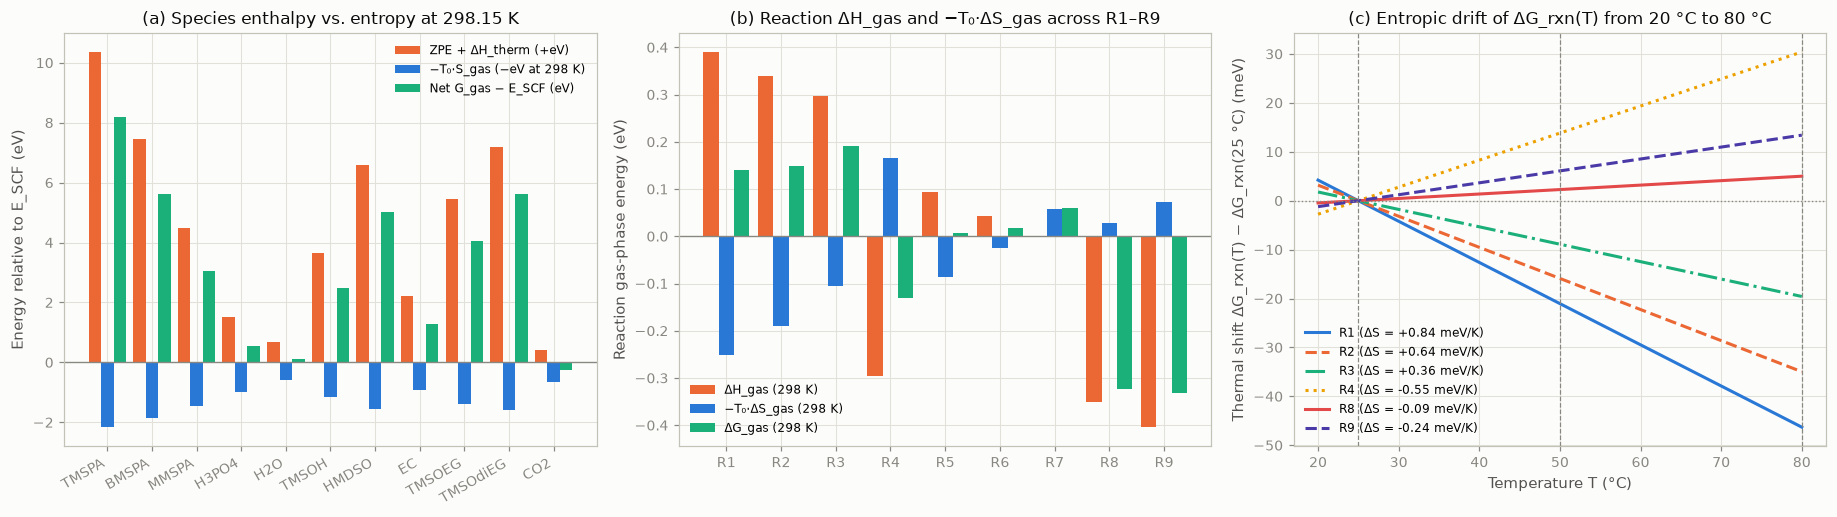

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16.8, 4.8))

# Panel (a): Species thermal enthalpy (ZPE + ΔH_therm) vs entropic term (-T0*S_gas)
ax = axes[0]
x = np.arange(len(df_v2_sp))
w = 0.28
ax.bar(x - w, df_v2_sp["ZPE (eV)"] + df_v2_sp["ΔH_therm (eV)"], width=w, color=SERIES[1], label="ZPE + ΔH_therm (+eV)")
ax.bar(x, -df_v2_sp["T₀·S_gas (eV)"], width=w, color=SERIES[0], label="−T₀·S_gas (−eV at 298 K)")
ax.bar(x + w, df_v2_sp["(G_gas − E_SCF) (eV)"], width=w, color=SERIES[2], label="Net G_gas − E_SCF (eV)")
ax.axhline(0, color=MUTED, linewidth=0.9)
ax.set_xticks(x)
ax.set_xticklabels(df_v2_sp["Species"], rotation=30, ha="right")
ax.set_ylabel("Energy relative to E_SCF (eV)")
ax.set_title("(a) Species enthalpy vs. entropy at 298.15 K")
ax.legend(loc="upper right", fontsize=8)

# Panel (b): Reaction ΔH_gas, -T0*ΔS_gas, and ΔG_gas across R1–R9
ax = axes[1]
xr = np.arange(len(df_rxn_v2))
ax.bar(xr - w, df_rxn_v2["ΔH_gas (eV)"], width=w, color=SERIES[1], label="ΔH_gas (298 K)")
ax.bar(xr, df_rxn_v2["−T₀·ΔS_gas (eV)"], width=w, color=SERIES[0], label="−T₀·ΔS_gas (298 K)")
ax.bar(xr + w, df_rxn_v2["ΔG_gas (25°C) (eV)"], width=w, color=SERIES[2], label="ΔG_gas (298 K)")
ax.axhline(0, color=MUTED, linewidth=0.9)
ax.set_xticks(xr)
ax.set_xticklabels(df_rxn_v2["Reaction"])
ax.set_ylabel("Reaction gas-phase energy (eV)")
ax.set_title("(b) Reaction ΔH_gas and −T₀·ΔS_gas across R1–R9")
ax.legend(loc="lower left", fontsize=8)

# Panel (c): Thermal drift ΔG_rxn(T) - ΔG_rxn(25 °C) from 20 °C to 80 °C
ax = axes[2]
T_C_grid = np.linspace(20.0, 80.0, 121)
T_K_grid = T_C_grid + 273.15
highlight_rxns = [("R1", SERIES[0], "-"), ("R2", SERIES[1], "--"), ("R3", SERIES[2], "-."), ("R4", SERIES[3], ":"), ("R8", SERIES[7], "-"), ("R9", SERIES[6], "--")]
for rxn_id, col, ls in highlight_rxns:
    row = df_rxn_v2[df_rxn_v2["Reaction"] == rxn_id].iloc[0]
    dS = row["ΔS_gas (meV/K)"]  # meV / K
    drift_mev = -(T_K_grid - 298.15) * dS
    ax.plot(T_C_grid, drift_mev, linestyle=ls, color=col, linewidth=2.0, label=f"{rxn_id} (ΔS = {dS:+.2f} meV/K)")
ax.axhline(0, color=MUTED, linestyle=":", linewidth=0.9)
ax.axvline(25.0, color=MUTED, linestyle="--", linewidth=0.8)
ax.axvline(50.0, color=MUTED, linestyle="--", linewidth=0.8)
ax.axvline(80.0, color=MUTED, linestyle="--", linewidth=0.8)
ax.set_xlabel("Temperature T (°C)")
ax.set_ylabel("Thermal shift ΔG_rxn(T) − ΔG_rxn(25 °C) (meV)")
ax.set_title("(c) Entropic drift of ΔG_rxn(T) from 20 °C to 80 °C")
ax.legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()


---
## 3. Variable 3 — COSMO-RS Miscibility (`lle`), Activity Coefficients ($\ln \gamma^\infty$), & Solvation Across Solvents (`EC` vs. `DEC` and 7 Solvents)

### Physical Meaning
For every molecule in `tms_v1`, `solvation_cosmors.jsonl` stores openCOSMO-RS 1.1a calculations across **7 battery & reference solvents** (`EC`, `DEC`, `DMC`, `PC`, `DME`, `DMSO`, `H2O`):
- **`dG_solv_kcal_mol` ($\Delta G_{\text{solv}}$):** Free energy of solvation (1 M ideal gas $\to$ 1 M solution).
- **`ln_gamma_inf` ($\ln \gamma_i^\infty$):** Natural log of the infinite-dilution activity coefficient relative to pure liquid solute $i$.
  - $\ln \gamma_i^\infty \le 0$: Solute $i$ prefers the solvent over its own pure liquid (thermodynamically favorable mixing).
  - $\ln \gamma_i^\infty \gg +1.5$: Strong thermodynamic repulsion between solute $i$ and the solvent.
- **`lle` (`"miscible"` vs. `"split"`):** Liquid-liquid equilibrium flag indicating whether the binary solute-solvent pair is completely miscible at $298.15\text{ K}$ or undergoes phase separation (`"split"`).

Let us inspect the complete species $\times$ solvent matrix for the 11 active model species.


In [8]:
SOLVENTS = ["EC", "DEC", "DMC", "propylene_carbonate", "DME", "DMSO", "H2O"]
SOLVENT_LABELS = {"propylene_carbonate": "PC"}

rows_v3 = []
for sp in MODEL_SPECIES:
    row = {"Species": sp, "Group": FAMILY_GROUP[sp]}
    for sv in SOLVENTS:
        lbl = SOLVENT_LABELS.get(sv, sv)
        rec = cosmo_by_id.get(sp, {}).get(sv, {})
        ln_g = rec.get("ln_gamma_inf", np.nan)
        lle = rec.get("lle", "—")
        row[f"ln γ∞ ({lbl})"] = ln_g
        row[f"LLE ({lbl})"] = lle
    row["EC vs DEC LLE"] = f"EC: {row['LLE (EC)']} | DEC: {row['LLE (DEC)']}"
    rows_v3.append(row)

df_v3 = pd.DataFrame(rows_v3)
display(Markdown("#### Table 3A — COSMO-RS Infinite-Dilution Activity Coefficient $\ln \gamma^\infty$ & Phase-Split (`lle`) in `EC` vs. `DEC` (and 5 Other Solvents)"))
show_table(
    df_v3[[
        "Species", "Group", "EC vs DEC LLE",
        "ln γ∞ (EC)", "ln γ∞ (DEC)", "ln γ∞ (DMC)", "ln γ∞ (PC)", "ln γ∞ (DME)", "ln γ∞ (DMSO)", "ln γ∞ (H2O)"
    ]].round(2)
)


#### Table 3A — COSMO-RS Infinite-Dilution Activity Coefficient $\ln \gamma^\infty$ & Phase-Split (`lle`) in `EC` vs. `DEC` (and 5 Other Solvents)

,Species,Group,EC vs DEC LLE,ln γ∞ (EC),ln γ∞ (DEC),ln γ∞ (DMC),ln γ∞ (PC),ln γ∞ (DME),ln γ∞ (DMSO),ln γ∞ (H2O)
0,TMSPA,Phosphate ladder,EC: split | DEC: miscible,5.86,0.02,0.65,3.09,-0.48,1.33,18.13
1,BMSPA,Phosphate ladder,EC: split | DEC: miscible,5.02,2.14,2.51,3.11,0.32,-2.30,11.57
2,MMSPA,Phosphate ladder,EC: split | DEC: miscible,3.70,3.83,4.00,2.59,0.36,-7.33,4.31
3,H3PO4,Phosphate ladder,EC: miscible | DEC: split,1.65,4.88,4.92,1.27,-0.80,-14.37,-3.59
4,H2O,Silyl / Water,EC: miscible | DEC: split,2.12,3.36,3.29,2.10,2.10,-2.34,0.00
5,TMSOH,Silyl / Water,EC: split | DEC: miscible,2.35,0.82,1.10,1.38,0.09,-1.25,5.69
6,HMDSO,Silyl / Water,EC: split | DEC: miscible,5.30,0.71,1.46,3.26,0.37,2.00,15.53
7,EC,Carbonate / Glycol,EC: self | DEC: miscible,0.00,1.07,0.57,0.09,1.33,-0.07,2.38
8,TMSOEG,Carbonate / Glycol,EC: split | DEC: miscible,2.74,0.34,0.64,1.50,0.05,0.20,7.63
9,TMSOdiEG,Carbonate / Glycol,EC: split | DEC: miscible,3.04,0.27,0.52,1.55,-0.16,-0.14,9.07


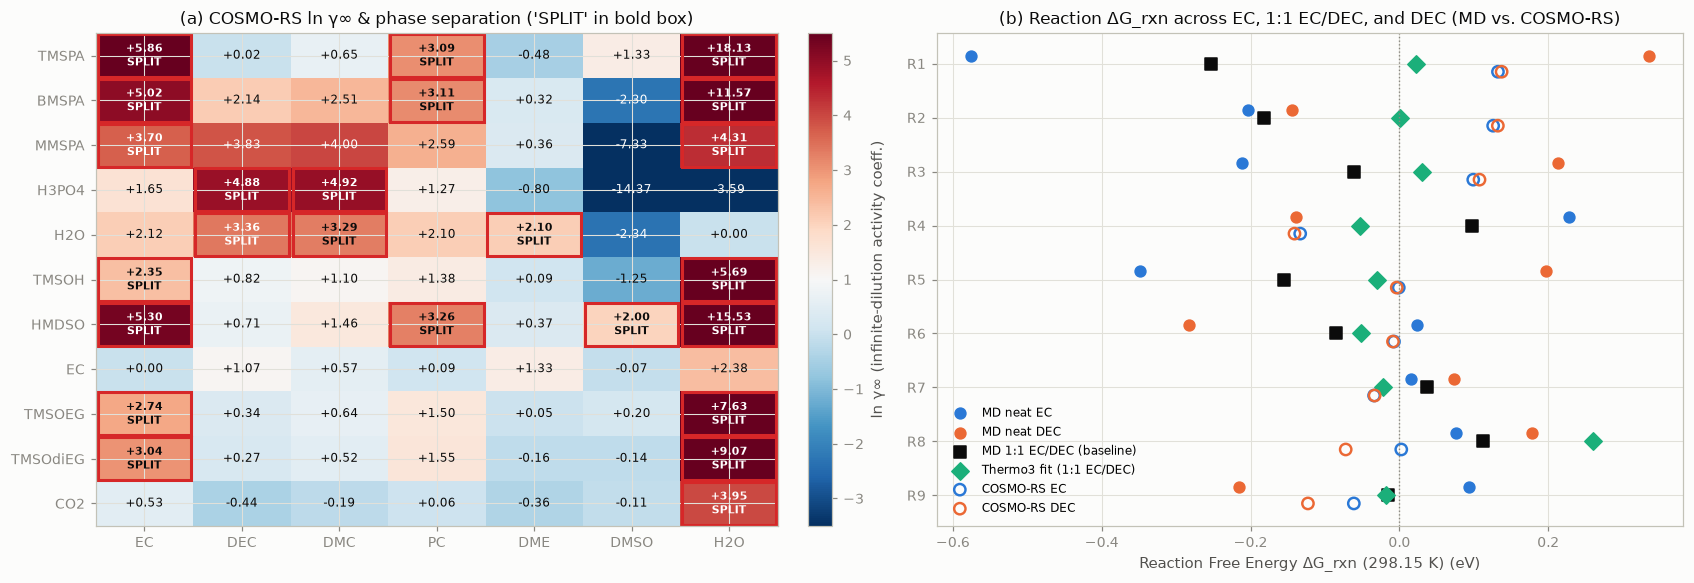

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4))

# Panel (a): Annotated heatmap of ln(gamma_inf) across the 11 model species x 7 solvents, marking 'split' pairs
ax = axes[0]
mat_lng = np.array([[cosmo_by_id.get(sp, {}).get(sv, {}).get("ln_gamma_inf", np.nan) for sv in SOLVENTS] for sp in MODEL_SPECIES])
mat_lle = [[cosmo_by_id.get(sp, {}).get(sv, {}).get("lle", "") for sv in SOLVENTS] for sp in MODEL_SPECIES]

im = ax.imshow(mat_lng, cmap="RdBu_r", vmin=-3.5, vmax=5.5, aspect="auto")
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("ln γ∞ (infinite-dilution activity coeff.)")

ax.set_xticks(np.arange(len(SOLVENTS)))
ax.set_xticklabels([SOLVENT_LABELS.get(sv, sv) for sv in SOLVENTS])
ax.set_yticks(np.arange(len(MODEL_SPECIES)))
ax.set_yticklabels(MODEL_SPECIES)
ax.set_title("(a) COSMO-RS ln γ∞ & phase separation ('SPLIT' in bold box)")

for i in range(len(MODEL_SPECIES)):
    for j in range(len(SOLVENTS)):
        val = mat_lng[i, j]
        lle = mat_lle[i][j]
        if np.isnan(val):
            continue
        is_split = (lle == "split")
        txt = f"{val:+.2f}\nSPLIT" if is_split else f"{val:+.2f}"
        text_col = "white" if abs(val - 1.0) > 2.3 else INK
        ax.text(
            j, i, txt, ha="center", va="center",
            fontsize=7.5 if is_split else 8,
            fontweight="bold" if is_split else "normal",
            color=text_col
        )
        if is_split:
            rect = plt.Rectangle((j - 0.48, i - 0.48), 0.96, 0.96, fill=False, edgecolor="#d62728", linewidth=2.0)
            ax.add_patch(rect)

# Panel (b): Reaction ΔG_rxn across solvent models (MD EC, MD 1:1 mix, MD DEC, COSMO EC, COSMO DEC, Thermo3 fit)
ax = axes[1]
sp_md_ec = np.array([v1_indexed.loc[sp, "MD EC (eV)"] for sp in MODEL_SPECIES])
sp_md_dec = np.array([v1_indexed.loc[sp, "MD DEC (eV)"] for sp in MODEL_SPECIES])
sp_md_mix = sp_dE_mix
sp_cos_ec = np.array([v1_indexed.loc[sp, "COSMO EC (eV)"] for sp in MODEL_SPECIES])
sp_cos_dec = np.array([v1_indexed.loc[sp, "COSMO DEC (eV)"] for sp in MODEL_SPECIES])
sp_th3 = sp_dE_mix + sp_shift_th3

rxn_ids = [r["id"] for r in RXN_LIST]
yr = np.arange(len(rxn_ids))

dG_md_ec = [float(S_mat[:, j] @ (sp_G0 + sp_md_ec)) for j in range(len(rxn_ids))]
dG_md_mix = [float(S_mat[:, j] @ (sp_G0 + sp_md_mix)) for j in range(len(rxn_ids))]
dG_md_dec = [float(S_mat[:, j] @ (sp_G0 + sp_md_dec)) for j in range(len(rxn_ids))]
dG_cos_ec = [float(S_mat[:, j] @ (sp_G0 + sp_cos_ec)) for j in range(len(rxn_ids))]
dG_cos_dec = [float(S_mat[:, j] @ (sp_G0 + sp_cos_dec)) for j in range(len(rxn_ids))]
dG_th3 = [float(S_mat[:, j] @ (sp_G0 + sp_th3)) for j in range(len(rxn_ids))]

ax.scatter(dG_md_ec, yr - 0.15, color=SERIES[0], marker="o", s=50, label="MD neat EC")
ax.scatter(dG_md_dec, yr - 0.15, color=SERIES[1], marker="o", s=50, label="MD neat DEC")
ax.scatter(dG_md_mix, yr, color=INK, marker="s", s=55, label="MD 1:1 EC/DEC (baseline)")
ax.scatter(dG_th3, yr, color=SERIES[2], marker="D", s=65, label="Thermo3 fit (1:1 EC/DEC)")
ax.scatter(dG_cos_ec, yr + 0.15, facecolors="none", edgecolors=SERIES[0], marker="o", s=55, linewidths=1.6, label="COSMO-RS EC")
ax.scatter(dG_cos_dec, yr + 0.15, facecolors="none", edgecolors=SERIES[1], marker="o", s=55, linewidths=1.6, label="COSMO-RS DEC")

ax.axvline(0, color=MUTED, linestyle=":", linewidth=0.9)
ax.set_yticks(yr)
ax.set_yticklabels(rxn_ids)
ax.invert_yaxis()
ax.set_xlabel("Reaction Free Energy ΔG_rxn (298.15 K) (eV)")
ax.set_title("(b) Reaction ΔG_rxn across EC, 1:1 EC/DEC, and DEC (MD vs. COSMO-RS)")
ax.legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()


---
## 4. Summary of Key Physical Takeaways

1. **Variable 1 (`sigma_hb_don`, `sigma_hb_acc`, `dipole_debye`):**
   - `sigma_hb_don` increases monotonically with each $-\text{OH}$ group created (`TMSPA` $0.00 \to$ `BMSPA` $6.52 \to$ `MMSPA` $14.28 \to$ `H3PO4` $23.52$), strongly correlating with the `EC`-vs-`DEC` solvation preference $\Delta E_{\text{solv}}^{\text{EC}} - \Delta E_{\text{solv}}^{\text{DEC}}$ (`+0.51 eV` for `TMSPA` vs. `-0.62 eV` for `H3PO4` in MD; `+0.14 eV` vs. `-0.10 eV` in COSMO-RS).
   - Every hydrolysis step (`R1`, `R2`, `R3`) has a positive net H-bond donor change ($\Delta\sigma_{\text{hb\_don}} = +2.64, +3.88, +5.36$), meaning polar `EC` stabilizes the products relative to apolar `DEC`.
2. **Variable 2 ($T_0 S_{\text{gas}}^\circ = H_{\text{gas}}^\circ - G_{\text{gas}}^\circ$ & $\Delta G_{\text{rxn}}(T)$):**
   - Using both `enthalpy_eh` and `gibbs_eh` requires **zero new fitted parameters** and corrects $\Delta G_{\text{rxn}}(T)$ at elevated temperatures ($50\,^\circ\text{C}$ and $80\,^\circ\text{C}$).
   - In `R1` (`TMSPA + H2O ⇌ BMSPA + TMSOH`) and `R2` (`BMSPA + H2O ⇌ MMSPA + TMSOH`), converting tight `H2O` ($T_0 S_{\text{gas}} = 0.583\text{ eV}$) into floppier `TMSOH` ($1.155\text{ eV}$) yields $\Delta S_{\text{gas}}^\circ = +0.842$ and $+0.636\text{ meV/K}$, shifting $\Delta G_{\text{rxn}}$ by **$-46.3\text{ meV}$** and **$-35.0\text{ meV}$** at $80\,^\circ\text{C}$ (increasing $K_{\text{eq}}(80\,^\circ\text{C})$ by **$4.58\times$** and **$3.16\times$** relative to frozen $G_{\text{gas}}(298\text{ K})$). Conversely, silanol condensation `R4` (`2 TMSOH ⇌ HMDSO + H2O`, $\Delta S_{\text{gas}}^\circ = -0.553\text{ meV/K}$) shifts by **$+30.4\text{ meV}$** at $80\,^\circ\text{C}$ ($0.37\times$ frozen $K_{\text{eq}}$).
3. **Variable 3 (COSMO-RS `lle` & $\ln \gamma^\infty$):**
   - **Complementary miscibility of `EC` and `DEC`:** In **neat `DEC`**, both `H2O` ($\ln \gamma^\infty = +3.36$, `split`) and `H3PO4` ($\ln \gamma^\infty = +4.88$, `split`) are flagged as phase-separating at high concentration, whereas all silylated species (`TMSPA`, `BMSPA`, `MMSPA`, `TMSOH`, `HMDSO`, `TMSOEG`, `TMSOdiEG`) are `miscible`.
   - Conversely, in **neat `EC`**, `H2O` and `H3PO4` are `miscible`, while the silylated species (`TMSPA` $\ln \gamma^\infty = +5.86$, `HMDSO` $+5.30$, `BMSPA` $+5.02$) are flagged as `split`. The `1:1 EC/DEC` co-solvent mixture acts as a mutual compatibilizer that keeps both ends of the hydrolysis network in a single liquid phase.
